In [2]:

from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

orders = pd.read_csv(io.BytesIO(uploaded["orders.csv"]))
picks = pd.read_csv(io.BytesIO(uploaded["picks.csv"]))
items = pd.read_csv(io.BytesIO(uploaded["items.csv"]))
workers = pd.read_csv(io.BytesIO(uploaded["workers.csv"]))
zones = pd.read_csv(io.BytesIO(uploaded["zones.csv"]))

print("All five raw datasets loaded successfully!")

Saving items.csv to items.csv
Saving orders.csv to orders.csv
Saving picks.csv to picks.csv
Saving README.txt to README.txt
Saving workers.csv to workers.csv
Saving zones.csv to zones.csv
All five raw datasets loaded successfully!


In [3]:

datasets = {
    "Orders": orders,
    "Picks": picks,
    "Items": items,
    "Workers": workers,
    "Zones": zones
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:\n", df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.head())



--- Orders ---
Shape: (262, 4)
Columns: ['order_id', 'item_count', 'priority', 'order_timestamp']
Missing values:
 order_id           0
item_count         8
priority           2
order_timestamp    6
dtype: int64
Duplicate rows: 1


,order_id,item_count,priority,order_timestamp
0,O00001,2.0,Low,2026-09-14 23:19:00
1,O00002,5.0,Normal,2026-09-05 08:50:00
2,O00003,1.0,High,NaN
3,O00004,5.0,High,2026-09-27 13:24:00
4,O00005,4.0,Normal,2026-09-10 05:21:00



--- Picks ---
Shape: (1143, 8)
Columns: ['pick_id', 'order_id', 'picker_id', 'zone_id', 'item_id', 'start_time', 'finish_time', 'quantity']
Missing values:
 pick_id         0
order_id       12
picker_id       0
zone_id         0
item_id         0
start_time     15
finish_time    40
quantity       21
dtype: int64
Duplicate rows: 1


,pick_id,order_id,picker_id,zone_id,item_id,start_time,finish_time,quantity
0,P000001,O00001,W029,B,I0025,2026-09-15 01:00:00,2026-09-15 01:09:00,7.0
1,P000002,O00002,W029,zone c,I0005,2026-09-05 10:46:00,2026-09-05 10:54:00,6.0
2,P000003,O00002,W032,B,I0019,2026-09-05 09:49:00,2026-09-05 10:02:00,4.0
3,P000004,O00002,W001,B,I0052,2026-09-05 09:54:00,2026-09-05 10:03:00,2.0
4,P000005,O00003,W029,H,I0056,2026-09-28 14:25:00,NaN,5.0



--- Items ---
Shape: (81, 4)
Columns: ['item_id', 'category', 'size', 'storage_class']
Missing values:
 item_id           0
category         10
size              3
storage_class     8
dtype: int64
Duplicate rows: 1


,item_id,category,size,storage_class
0,I0001,Fragile Goods,Small,Standard
1,I0002,Small Parts,Small,Fragile
2,I0003,NaN,Small,Climate-Controlled
3,I0004,Electronics,Small,Standard
4,I0005,Apparel,Small,Climate-Controlled



--- Workers ---
Shape: (33, 3)
Columns: ['picker_id', 'shift', 'experience_band']
Missing values:
 picker_id          0
shift              5
experience_band    8
dtype: int64
Duplicate rows: 0


,picker_id,shift,experience_band
0,W001,Night,Intermediate
1,W002,Night,NaN
2,W003,Night,Intermediate
3,W004,Evening,NaN
4,W005,NaN,Intermediate



--- Zones ---
Shape: (9, 3)
Columns: ['zone_id', 'zone_type', 'distance_band']
Missing values:
 zone_id          0
zone_type        0
distance_band    1
dtype: int64
Duplicate rows: 0


,zone_id,zone_type,distance_band
0,A,Fast-moving,Near
1,B,Bulk,Far
2,C,Small Parts,Medium
3,D,Fragile,NaN
4,E,Fast-moving,Medium


In [4]:

# STEP 1: Investigate data-quality issues

print("ORDERS")
print("Duplicate order IDs:",
      orders["order_id"].duplicated().sum())
print("Invalid item counts:",
      (orders["item_count"].notna() &
       (orders["item_count"] <= 0)).sum())

print("\nPICKS")
print("Duplicate pick IDs:",
      picks["pick_id"].duplicated().sum())
print("Negative quantities:",
      (picks["quantity"] < 0).sum())

# Convert timestamps for validation without overwriting raw values
start = pd.to_datetime(picks["start_time"], errors="coerce")
finish = pd.to_datetime(picks["finish_time"], errors="coerce")

print("Unparseable/missing start times:", start.isna().sum())
print("Unparseable/missing finish times:", finish.isna().sum())
print("Negative durations:",
      ((finish - start).dt.total_seconds() < 0).sum())

print("\nWORKERS")
print(workers["picker_id"].value_counts().head(10))

print("\nZONE LABELS IN PICKS")
print(picks["zone_id"].value_counts(dropna=False))

print("\nITEM CATEGORIES")
print(items["category"].value_counts(dropna=False))


ORDERS
Duplicate order IDs: 2
Invalid item counts: 0

PICKS
Duplicate pick IDs: 2
Negative quantities: 18
Unparseable/missing start times: 15
Unparseable/missing finish times: 40
Negative durations: 19

WORKERS
picker_id
W007    2
W001    1
W003    1
W002    1
W004    1
W005    1
W006    1
W008    1
W009    1
W010    1
Name: count, dtype: int64

ZONE LABELS IN PICKS
zone_id
H           151
G           149
A           139
E           138
F           137
D           136
C           132
B           128
 zone c       5
 zone a       5
 zone e       5
 zone f       5
 zone b       5
 zone h       5
 zone g       2
 zone d       1
Name: count, dtype: int64

ITEM CATEGORIES
category
Bulk Materials    16
Fragile Goods     13
Small Parts       13
NaN               10
Electronics        9
Apparel            9
Home Goods         9
 electronics       2
Name: count, dtype: int64


In [5]:

# STEP 2: Preserve the original data

orders_raw = orders.copy(deep=True)
picks_raw = picks.copy(deep=True)
items_raw = items.copy(deep=True)
workers_raw = workers.copy(deep=True)
zones_raw = zones.copy(deep=True)

print("Raw backup copies created successfully.")


Raw backup copies created successfully.


In [6]:

# STEP 3: Clean orders

orders_clean = orders_raw.drop_duplicates().copy()

# Standardize order IDs and priority labels
orders_clean["order_id"] = (
    orders_clean["order_id"]
    .astype("string").str.strip().str.upper()
)

orders_clean["priority"] = (
    orders_clean["priority"]
    .astype("string").str.strip().str.title()
)

# Normalize known priority variants
orders_clean["priority"] = orders_clean["priority"].replace({
    "High": "High",
    "Normal": "Normal",
    "Low": "Low",
    "Urgent": "Urgent"
})

# Parse timestamp safely
orders_clean["order_timestamp"] = pd.to_datetime(
    orders_clean["order_timestamp"], errors="coerce"
)

# Identify conflicting order IDs
order_conflicts = orders_clean[
    orders_clean["order_id"].notna()
    & orders_clean["order_id"].duplicated(keep=False)
].sort_values("order_id")

print("Rows after exact-duplicate removal:", len(orders_clean))
print("Repeated order IDs requiring investigation:")
display(order_conflicts)


Rows after exact-duplicate removal: 261
Repeated order IDs requiring investigation:


,order_id,item_count,priority,order_timestamp
21,O00022,6.0,Urgent,2026-09-05 14:40:00
261,O00022,99.0,Urgent,2026-09-15 12:00:00


In [7]:

# STEP 4: Clean picks

picks_clean = picks_raw.drop_duplicates().copy()

# Normalize identifiers
for col in ["pick_id", "order_id", "picker_id", "item_id"]:
    picks_clean[col] = (
        picks_clean[col].astype("string").str.strip().str.upper()
    )

# Standardize zone labels: " zone c " becomes "C"
picks_clean["zone_id"] = (
    picks_clean["zone_id"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"^ZONE\s*", "", regex=True)
)

# Parse timestamps
picks_clean["start_time"] = pd.to_datetime(
    picks_clean["start_time"], errors="coerce"
)
picks_clean["finish_time"] = pd.to_datetime(
    picks_clean["finish_time"], errors="coerce"
)

# Calculate duration in minutes
picks_clean["pick_time_min"] = (
    picks_clean["finish_time"] - picks_clean["start_time"]
).dt.total_seconds() / 60

# Flag problematic records instead of silently deleting them
picks_clean["missing_timestamp"] = (
    picks_clean["start_time"].isna()
    | picks_clean["finish_time"].isna()
)

picks_clean["negative_duration"] = (
    picks_clean["pick_time_min"] < 0
)

picks_clean["invalid_quantity"] = (
    picks_clean["quantity"].isna()
    | (picks_clean["quantity"] <= 0)
)

print("Pick records:", len(picks_clean))
print("Missing timestamps:",
      picks_clean["missing_timestamp"].sum())
print("Negative durations:",
      picks_clean["negative_duration"].sum())
print("Invalid quantities:",
      picks_clean["invalid_quantity"].sum())

display(picks_clean.head())


Pick records: 1142
Missing timestamps: 55
Negative durations: 19
Invalid quantities: 39


,pick_id,order_id,picker_id,zone_id,item_id,start_time,finish_time,quantity,pick_time_min,missing_timestamp,negative_duration,invalid_quantity
0,P000001,O00001,W029,B,I0025,2026-09-15 01:00:00,2026-09-15 01:09:00,7.0,9.0,False,False,False
1,P000002,O00002,W029,C,I0005,2026-09-05 10:46:00,2026-09-05 10:54:00,6.0,8.0,False,False,False
2,P000003,O00002,W032,B,I0019,2026-09-05 09:49:00,2026-09-05 10:02:00,4.0,13.0,False,False,False
3,P000004,O00002,W001,B,I0052,2026-09-05 09:54:00,2026-09-05 10:03:00,2.0,9.0,False,False,False
4,P000005,O00003,W029,H,I0056,2026-09-28 14:25:00,NaT,5.0,NaN,True,False,False


In [8]:
# Remove exact duplicate rows
items_clean = items_raw.drop_duplicates().copy()

# Standardize text columns
for col in ["item_id", "category", "size", "storage_class"]:
    items_clean[col] = (
        items_clean[col]
        .astype("string")
        .str.strip()
    )

items_clean["item_id"] = items_clean["item_id"].str.upper()
items_clean["category"] = items_clean["category"].str.title()
items_clean["size"] = items_clean["size"].str.title()
items_clean["storage_class"] = items_clean["storage_class"].str.title()

# Inspect missing values and repeated item IDs
print("Items dataset shape:", items_clean.shape)
print("\nMissing values:")
print(items_clean.isna().sum())

print("\nRepeated item IDs:")
display(
    items_clean[
        items_clean["item_id"].duplicated(keep=False)
    ].sort_values("item_id")
)

print("\nCategory values:")
print(items_clean["category"].value_counts(dropna=False))

Items dataset shape: (80, 4)

Missing values:
item_id           0
category         10
size              3
storage_class     8
dtype: int64

Repeated item IDs:


,item_id,category,size,storage_class



Category values:
category
Bulk Materials    16
Small Parts       13
Fragile Goods     12
Electronics       11
<NA>              10
Apparel            9
Home Goods         9
Name: count, dtype: Int64


In [9]:
# Remove exact duplicate rows
workers_clean = workers_raw.drop_duplicates().copy()

# Standardize text
workers_clean["picker_id"] = (
    workers_clean["picker_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

workers_clean["shift"] = (
    workers_clean["shift"]
    .astype("string")
    .str.strip()
    .str.title()
)

workers_clean["experience_band"] = (
    workers_clean["experience_band"]
    .astype("string")
    .str.strip()
    .str.title()
)

print("Workers dataset shape:", workers_clean.shape)

print("\nMissing values:")
print(workers_clean.isna().sum())

print("\nRepeated picker IDs requiring investigation:")
display(
    workers_clean[
        workers_clean["picker_id"].duplicated(keep=False)
    ].sort_values("picker_id")
)

print("\nShift values:")
print(workers_clean["shift"].value_counts(dropna=False))

print("\nExperience values:")
print(workers_clean["experience_band"].value_counts(dropna=False))

Workers dataset shape: (33, 3)

Missing values:
picker_id          0
shift              5
experience_band    8
dtype: int64

Repeated picker IDs requiring investigation:


,picker_id,shift,experience_band
6,W007,Night,<NA>
32,W007,Night,Intermediate



Shift values:
shift
Night      19
Morning     6
<NA>        5
Evening     3
Name: count, dtype: Int64

Experience values:
experience_band
Intermediate    10
Experienced      9
<NA>             8
Beginner         6
Name: count, dtype: Int64


In [10]:
# Remove exact duplicate rows
zones_clean = zones_raw.drop_duplicates().copy()

# Standardize text columns
zones_clean["zone_id"] = (
    zones_clean["zone_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

zones_clean["zone_type"] = (
    zones_clean["zone_type"]
    .astype("string")
    .str.strip()
    .str.title()
)

zones_clean["distance_band"] = (
    zones_clean["distance_band"]
    .astype("string")
    .str.strip()
    .str.title()
)

print("Zones dataset shape:", zones_clean.shape)

print("\nMissing values:")
print(zones_clean.isna().sum())

print("\nRepeated zone IDs requiring investigation:")
display(
    zones_clean[
        zones_clean["zone_id"].duplicated(keep=False)
    ].sort_values("zone_id")
)

print("\nZone types:")
print(zones_clean["zone_type"].value_counts(dropna=False))

Zones dataset shape: (9, 3)

Missing values:
zone_id          0
zone_type        0
distance_band    1
dtype: int64

Repeated zone IDs requiring investigation:


,zone_id,zone_type,distance_band
1,B,Bulk,Far
8,B,Bulk Storage,Far



Zone types:
zone_type
Fast-Moving     2
Bulk            2
Small Parts     2
Fragile         1
Cold Storage    1
Bulk Storage    1
Name: count, dtype: Int64


In [11]:
datasets = {
    "Orders": orders_clean,
    "Picks": picks_clean,
    "Items": items_clean,
    "Workers": workers_clean,
    "Zones": zones_clean
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Missing values:", df.isna().sum().sum())

# Check repeated keys
print("\nRepeated order IDs:",
      orders_clean["order_id"].duplicated().sum())

print("Repeated pick IDs:",
      picks_clean["pick_id"].duplicated().sum())

print("Repeated item IDs:",
      items_clean["item_id"].duplicated().sum())

print("Repeated picker IDs:",
      workers_clean["picker_id"].duplicated().sum())

print("Repeated zone IDs:",
      zones_clean["zone_id"].duplicated().sum())


--- Orders ---
Rows: 261
Missing values: 17

--- Picks ---
Rows: 1142
Missing values: 143

--- Items ---
Rows: 80
Missing values: 21

--- Workers ---
Rows: 33
Missing values: 13

--- Zones ---
Rows: 9
Missing values: 1

Repeated order IDs: 1
Repeated pick IDs: 1
Repeated item IDs: 0
Repeated picker IDs: 1
Repeated zone IDs: 1


In [12]:
print("1. REPEATED ORDER IDs")
display(
    orders_clean[
        orders_clean["order_id"].duplicated(keep=False)
    ].sort_values("order_id")
)

print("\n2. REPEATED PICK IDs")
display(
    picks_clean[
        picks_clean["pick_id"].duplicated(keep=False)
    ].sort_values("pick_id")
)

print("\n3. REPEATED PICKER IDs")
display(
    workers_clean[
        workers_clean["picker_id"].duplicated(keep=False)
    ].sort_values("picker_id")
)

print("\n4. REPEATED ZONE IDs")
display(
    zones_clean[
        zones_clean["zone_id"].duplicated(keep=False)
    ].sort_values("zone_id")
)

1. REPEATED ORDER IDs


,order_id,item_count,priority,order_timestamp
21,O00022,6.0,Urgent,2026-09-05 14:40:00
261,O00022,99.0,Urgent,2026-09-15 12:00:00



2. REPEATED PICK IDs


,pick_id,order_id,picker_id,zone_id,item_id,start_time,finish_time,quantity,pick_time_min,missing_timestamp,negative_duration,invalid_quantity
45,P000046,O00014,W026,C,I0064,2026-09-25 06:53:00,2026-09-25 06:59:00,4.0,6.0,False,False,False
1142,P000046,O00014,W026,C,I0064,2026-09-25 06:53:00,2026-09-20 23:59:00,4.0,-6174.0,False,True,False



3. REPEATED PICKER IDs


,picker_id,shift,experience_band
6,W007,Night,<NA>
32,W007,Night,Intermediate



4. REPEATED ZONE IDs


,zone_id,zone_type,distance_band
1,B,Bulk,Far
8,B,Bulk Storage,Far


In [13]:

# STEP 8: RESOLVE CONFLICTS AND VERIFY DATASETS

# 1. Preserve conflicting records for audit
order_conflicts = orders_clean[
    orders_clean["order_id"].eq("O00022")
].copy()

pick_conflicts = picks_clean[
    picks_clean["pick_id"].eq("P000046")
].copy()

worker_conflicts = workers_clean[
    workers_clean["picker_id"].eq("W007")
].copy()

zone_conflicts = zones_clean[
    zones_clean["zone_id"].eq("B")
].copy()

# 2. Resolve duplicate order ID: keep the earlier timestamp
orders_clean = orders_clean.sort_values(
    "order_timestamp", na_position="last"
).drop_duplicates(subset="order_id", keep="first").copy()

# 3. Resolve duplicate pick ID: keep the valid-duration record
picks_clean["pick_time_min"] = (
    picks_clean["finish_time"] - picks_clean["start_time"]
).dt.total_seconds() / 60

picks_clean = picks_clean.sort_values(
    "pick_time_min", ascending=False
).drop_duplicates(subset="pick_id", keep="first").copy()

# 4. Resolve duplicate worker IDs by consolidating non-missing values
workers_clean = (
    workers_clean.groupby("picker_id", as_index=False)
    .agg({
        "shift": "first",
        "experience_band": "first"
    })
)

# 5. Standardize zone labels and retain one row per zone
zones_clean["zone_type"] = (
    zones_clean["zone_type"].astype("string").str.strip()
    .replace({"Bulk": "Bulk Storage"})
)

zones_clean = zones_clean.drop_duplicates(
    subset="zone_id", keep="first"
).copy()

# 6. Verify unique identifiers
print("DATASET VERIFICATION")
for name, df, key in [
    ("Orders", orders_clean, "order_id"),
    ("Picks", picks_clean, "pick_id"),
    ("Items", items_clean, "item_id"),
    ("Workers", workers_clean, "picker_id"),
    ("Zones", zones_clean, "zone_id")
]:
    print(
        f"{name}: {len(df)} rows | "
        f"Repeated {key}: {df[key].duplicated().sum()}"
    )

print("\nAUDIT RECORDS PRESERVED")
print("Order conflict rows:", len(order_conflicts))
print("Pick conflict rows:", len(pick_conflicts))
print("Worker conflict rows:", len(worker_conflicts))
print("Zone conflict rows:", len(zone_conflicts))

print("\nWORKER W007 AFTER CONSOLIDATION")
display(workers_clean[workers_clean["picker_id"] == "W007"])

print("\nZONE B AFTER STANDARDIZATION")
display(zones_clean[zones_clean["zone_id"] == "B"])


DATASET VERIFICATION
Orders: 260 rows | Repeated order_id: 0
Picks: 1141 rows | Repeated pick_id: 0
Items: 80 rows | Repeated item_id: 0
Workers: 32 rows | Repeated picker_id: 0
Zones: 8 rows | Repeated zone_id: 0

AUDIT RECORDS PRESERVED
Order conflict rows: 2
Pick conflict rows: 2
Worker conflict rows: 2
Zone conflict rows: 2

WORKER W007 AFTER CONSOLIDATION


,picker_id,shift,experience_band
6,W007,Night,Intermediate



ZONE B AFTER STANDARDIZATION


,zone_id,zone_type,distance_band
1,B,Bulk Storage,Far


In [14]:

# STEP 10: CLEAN, MERGE, AND ENGINEER FEATURES

import pandas as pd
import numpy as np

# Work on copies
o = orders_clean.copy()
p = picks_clean.copy()
i = items_clean.copy()
w = workers_clean.copy()
z = zones_clean.copy()

# Ensure timestamps are datetime
o["order_timestamp"] = pd.to_datetime(
    o["order_timestamp"], errors="coerce"
)
p["start_time"] = pd.to_datetime(
    p["start_time"], errors="coerce"
)
p["finish_time"] = pd.to_datetime(
    p["finish_time"], errors="coerce"
)

# Standardize numeric columns
o["item_count"] = pd.to_numeric(o["item_count"], errors="coerce")
p["quantity"] = pd.to_numeric(p["quantity"], errors="coerce")

# Remove orders with missing essential identifiers
o = o.dropna(subset=["order_id"]).copy()

# Keep missing item counts as missing for now; flag them
o["item_count_missing"] = o["item_count"].isna()
o.loc[o["item_count"] <= 0, "item_count"] = np.nan

# Fill missing descriptive categories
for col in ["priority"]:
    o[col] = o[col].fillna("Unknown")

for col in ["category", "size", "storage_class"]:
    i[col] = i[col].fillna("Unknown")

for col in ["shift", "experience_band"]:
    w[col] = w[col].fillna("Unknown")

for col in ["zone_type", "distance_band"]:
    z[col] = z[col].fillna("Unknown")

# Recalculate pick duration
p["pick_time_min"] = (
    p["finish_time"] - p["start_time"]
).dt.total_seconds() / 60

# Keep only valid records for duration analysis
p = p[
    p["start_time"].notna()
    & p["finish_time"].notna()
    & p["pick_time_min"].ge(0)
    & p["quantity"].notna()
    & p["quantity"].gt(0)
].copy()

# Remove rows with missing essential IDs
p = p.dropna(
    subset=["pick_id", "order_id", "picker_id", "zone_id", "item_id"]
).copy()

# Keep valid foreign-key references
p = p[p["order_id"].isin(o["order_id"])]
p = p[p["item_id"].isin(i["item_id"])]
p = p[p["picker_id"].isin(w["picker_id"])]
p = p[p["zone_id"].isin(z["zone_id"])]

# Merge pick-level data with order, item, worker and zone details
analysis_df = p.merge(
    o, on="order_id", how="left", validate="many_to_one"
)
analysis_df = analysis_df.merge(
    i, on="item_id", how="left", validate="many_to_one"
)
analysis_df = analysis_df.merge(
    w, on="picker_id", how="left", validate="many_to_one"
)
analysis_df = analysis_df.merge(
    z, on="zone_id", how="left", validate="many_to_one"
)

# Feature engineering
analysis_df["order_hour"] = analysis_df["order_timestamp"].dt.hour
analysis_df["order_day"] = analysis_df["order_timestamp"].dt.day_name()
analysis_df["order_size_group"] = pd.cut(
    analysis_df["item_count"],
    bins=[0, 5, 10, 20, np.inf],
    labels=["Small (1-5)", "Medium (6-10)",
            "Large (11-20)", "Very Large (21+)"]
)
analysis_df["pick_time_per_unit"] = (
    analysis_df["pick_time_min"] / analysis_df["quantity"]
)

# Save cleaned outputs
orders_cleaned = o
picks_cleaned = p

analysis_df.to_csv("warehouse_analysis_cleaned.csv", index=False)
print("Cleaning and merging completed.")
print("Analysis dataset shape:", analysis_df.shape)
print("\nMissing values in merged data:")
print(analysis_df.isna().sum().sort_values(ascending=False).head(12))
print("\nSample merged data:")
display(analysis_df.head())


Cleaning and merging completed.
Analysis dataset shape: (1013, 27)

Missing values in merged data:
item_count           32
order_size_group     32
order_hour           22
order_timestamp      22
order_day            22
start_time            0
item_id               0
zone_id               0
pick_id               0
order_id              0
picker_id             0
negative_duration     0
dtype: int64

Sample merged data:


,pick_id,order_id,picker_id,zone_id,item_id,start_time,finish_time,quantity,pick_time_min,missing_timestamp,...,size,storage_class,shift,experience_band,zone_type,distance_band,order_hour,order_day,order_size_group,pick_time_per_unit
0,P000440,O00104,W012,G,I0075,2026-09-29 05:15:00,2026-09-29 05:33:00,3.0,18.0,False,...,Small,Standard,Night,Beginner,Cold Storage,Far,5.0,Tuesday,Large (11-20),6.000000
1,P000293,O00069,W008,G,I0011,2026-09-20 18:35:00,2026-09-20 18:52:00,5.0,17.0,False,...,Medium,Climate-Controlled,Night,Beginner,Cold Storage,Far,18.0,Sunday,Medium (6-10),3.400000
2,P000837,O00196,W032,B,I0045,2026-09-04 16:43:00,2026-09-04 17:00:00,6.0,17.0,False,...,Large,Climate-Controlled,Evening,Beginner,Bulk Storage,Far,15.0,Friday,Large (11-20),2.833333
3,P000426,O00101,W006,G,I0036,2026-09-24 05:33:00,2026-09-24 05:49:00,6.0,16.0,False,...,Small,Unknown,Night,Beginner,Cold Storage,Far,4.0,Thursday,Small (1-5),2.666667
4,P000880,O00204,W032,D,I0049,2026-09-10 02:08:00,2026-09-10 02:24:00,1.0,16.0,False,...,Medium,Standard,Evening,Beginner,Fragile,Unknown,1.0,Thursday,Medium (6-10),16.000000


========== OVERALL WAREHOUSE SUMMARY ==========


,Metric,Value
0,Total merged pick records,1013.00
1,Valid pick records,1013.00
2,Unique orders,252.00
3,Unique pickers,32.00
4,Unique zones,8.00
5,Average pick time (minutes),7.78
6,Median pick time (minutes),8.00
7,Average quantity per pick,3.88
8,Average pick time per unit (minutes),2.76



========== PERFORMANCE BY ZONE ==========


,zone_id,zone_type,Pick_Records,Avg_Pick_Min,Median_Pick_Min,Avg_Quantity
6,G,Cold Storage,131,10.69,11.0,3.93
3,D,Fragile,122,10.01,10.0,4.00
1,B,Bulk Storage,122,9.39,9.0,3.86
5,F,Bulk Storage,124,7.64,8.0,3.90
2,C,Small Parts,120,7.42,7.0,3.81
7,H,Small Parts,136,6.35,7.0,4.05
4,E,Fast-Moving,127,5.76,6.0,3.62
0,A,Fast-Moving,131,5.18,5.0,3.82



========== PERFORMANCE BY ORDER SIZE ==========


...

,experience_band,Pick_Records,Avg_Pick_Min,Median_Pick_Min
0,Beginner,184,9.57,9.0
3,Unknown,233,7.70,7.0
2,Intermediate,324,7.69,8.0
1,Experienced,272,6.74,7.0



========== PERFORMANCE BY ITEM CATEGORY ==========


,category,Pick_Records,Avg_Pick_Min,Median_Pick_Min,Avg_Quantity
3,Fragile Goods,154,8.08,7.5,4.08
0,Apparel,114,7.93,8.0,3.98
5,Small Parts,164,7.84,8.0,3.70
6,Unknown,108,7.83,8.0,3.79
4,Home Goods,99,7.73,7.0,3.93
2,Electronics,166,7.62,7.0,3.93
1,Bulk Materials,208,7.53,7.5,3.79



========== HOURLY WORKLOAD PROXY ==========


,start_hour,Pick_Records,Avg_Pick_Min
0,0,40,6.85
1,1,56,7.38
2,2,36,8.31
3,3,52,7.17
4,4,28,8.29
5,5,39,7.82
6,6,31,8.16
7,7,38,8.00
8,8,41,7.80
9,9,58,7.79


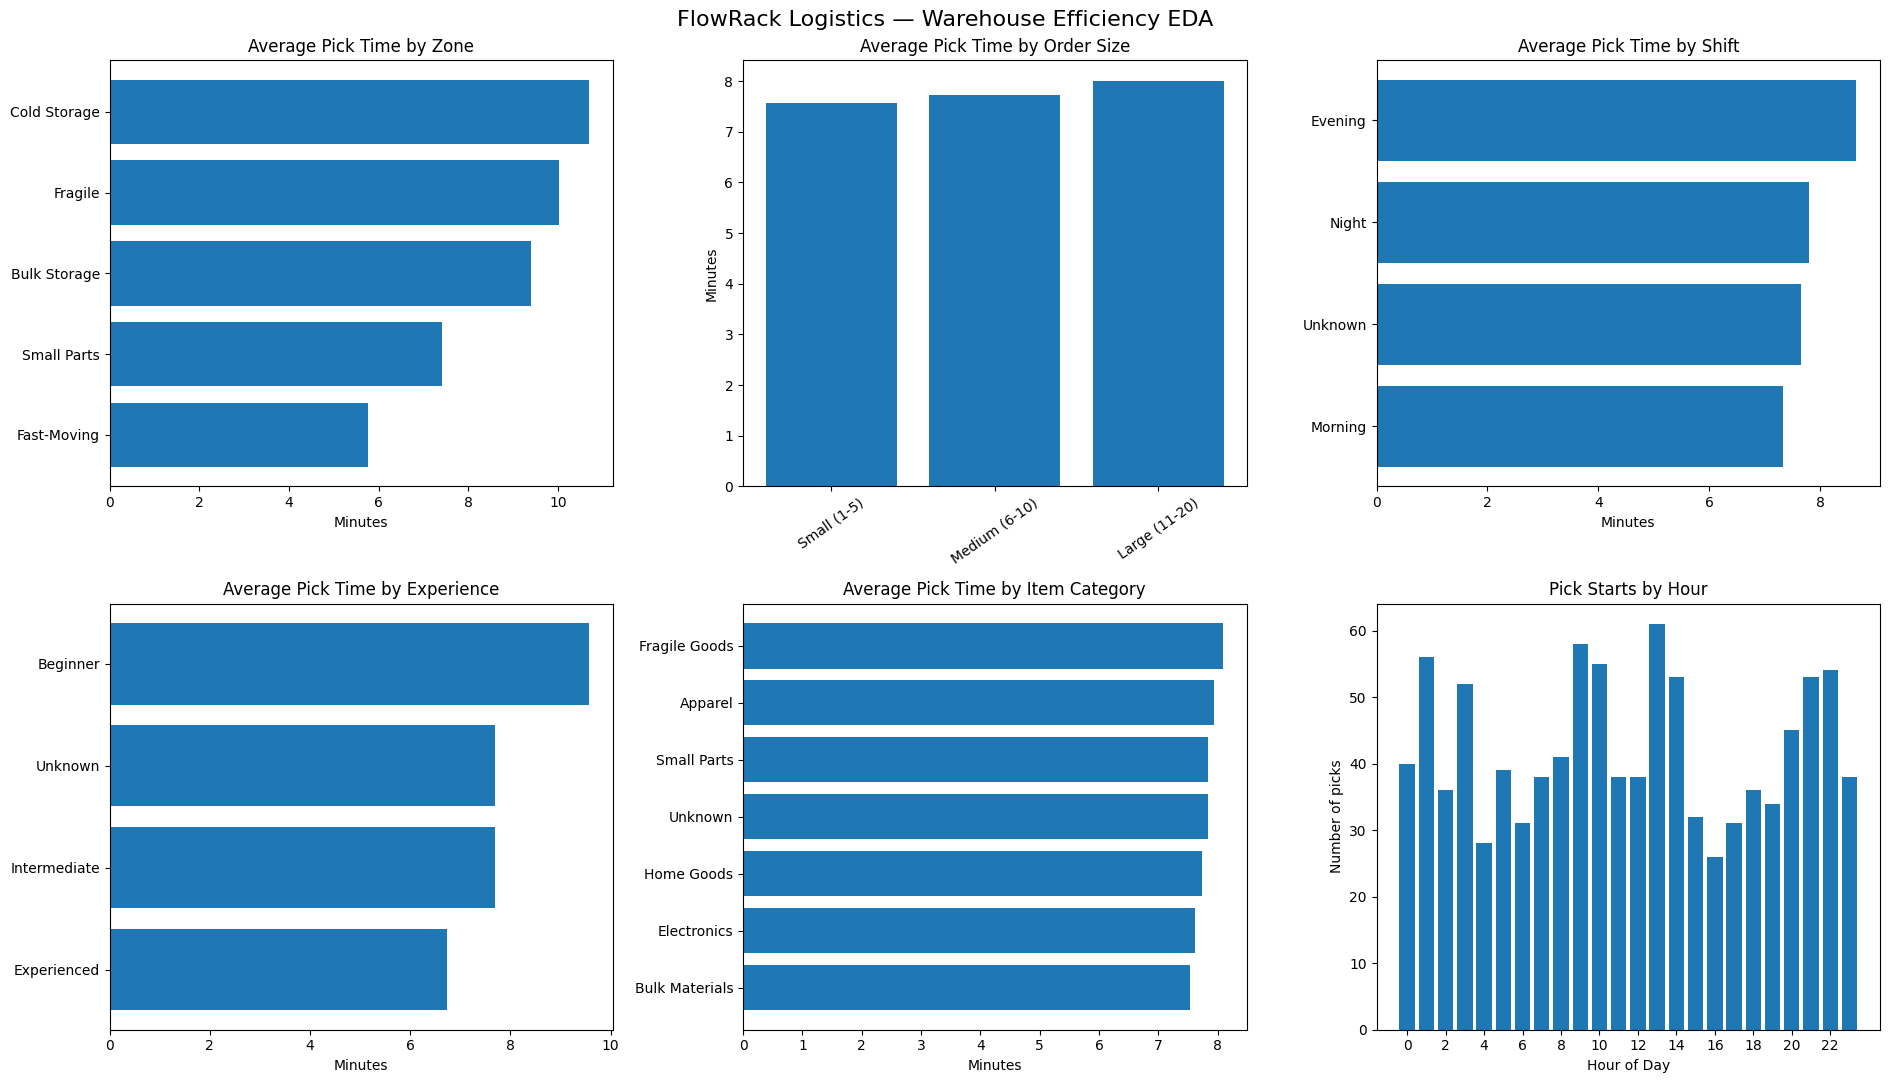


EDA completed successfully.
Seven summary CSV files have been saved in the Colab working directory.


In [15]:

# STEP 11: COMPLETE WAREHOUSE EDA IN ONE CELL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

df = analysis_df.copy()

# Ensure correct data types
df["pick_time_min"] = pd.to_numeric(df["pick_time_min"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["item_count"] = pd.to_numeric(df["item_count"], errors="coerce")
df["start_time"] = pd.to_datetime(df["start_time"], errors="coerce")

# Create a valid analysis subset for duration-related metrics
valid = df[
    df["pick_time_min"].notna()
    & (df["pick_time_min"] >= 0)
    & df["quantity"].notna()
    & (df["quantity"] > 0)
].copy()

# 1. Overall performance summary
overall = pd.DataFrame({
    "Metric": [
        "Total merged pick records",
        "Valid pick records",
        "Unique orders",
        "Unique pickers",
        "Unique zones",
        "Average pick time (minutes)",
        "Median pick time (minutes)",
        "Average quantity per pick",
        "Average pick time per unit (minutes)"
    ],
    "Value": [
        len(df),
        len(valid),
        df["order_id"].nunique(),
        df["picker_id"].nunique(),
        df["zone_id"].nunique(),
        round(valid["pick_time_min"].mean(), 2),
        round(valid["pick_time_min"].median(), 2),
        round(valid["quantity"].mean(), 2),
        round((valid["pick_time_min"] / valid["quantity"]).mean(), 2)
    ]
})

# 2. Group-wise performance summaries
zone_summary = (
    valid.groupby(["zone_id", "zone_type"], dropna=False)
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean"),
        Median_Pick_Min=("pick_time_min", "median"),
        Avg_Quantity=("quantity", "mean")
    ).reset_index()
)

size_summary = (
    valid.groupby("order_size_group", observed=True, dropna=False)
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean"),
        Median_Pick_Min=("pick_time_min", "median")
    ).reset_index()
)

shift_summary = (
    valid.groupby("shift", dropna=False)
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean"),
        Median_Pick_Min=("pick_time_min", "median"),
        Avg_Quantity=("quantity", "mean")
    ).reset_index()
)

experience_summary = (
    valid.groupby("experience_band", dropna=False)
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean"),
        Median_Pick_Min=("pick_time_min", "median")
    ).reset_index()
)

category_summary = (
    valid.groupby("category", dropna=False)
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean"),
        Median_Pick_Min=("pick_time_min", "median"),
        Avg_Quantity=("quantity", "mean")
    ).reset_index()
)

# Round numeric summary values
for table in [
    zone_summary, size_summary, shift_summary,
    experience_summary, category_summary
]:
    numeric_cols = table.select_dtypes(include="number").columns
    table[numeric_cols] = table[numeric_cols].round(2)

# 3. Hourly workload proxy: number of picks started each hour
valid["start_hour"] = valid["start_time"].dt.hour

hourly_summary = (
    valid.dropna(subset=["start_hour"])
    .groupby("start_hour")
    .agg(
        Pick_Records=("pick_id", "count"),
        Avg_Pick_Min=("pick_time_min", "mean")
    ).reset_index()
)

hourly_summary["Avg_Pick_Min"] = hourly_summary["Avg_Pick_Min"].round(2)

# 4. Display the findings
print("========== OVERALL WAREHOUSE SUMMARY ==========")
display(overall)

print("\n========== PERFORMANCE BY ZONE ==========")
display(zone_summary.sort_values("Avg_Pick_Min", ascending=False))

print("\n========== PERFORMANCE BY ORDER SIZE ==========")
display(size_summary)

print("\n========== PERFORMANCE BY SHIFT ==========")
display(shift_summary.sort_values("Avg_Pick_Min", ascending=False))

print("\n========== PERFORMANCE BY EXPERIENCE ==========")
display(experience_summary.sort_values("Avg_Pick_Min", ascending=False))

print("\n========== PERFORMANCE BY ITEM CATEGORY ==========")
display(category_summary.sort_values("Avg_Pick_Min", ascending=False))

print("\n========== HOURLY WORKLOAD PROXY ==========")
display(hourly_summary)

# 5. Create six charts
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

zone_plot = zone_summary.sort_values("Avg_Pick_Min")
axes[0, 0].barh(zone_plot["zone_type"], zone_plot["Avg_Pick_Min"])
axes[0, 0].set_title("Average Pick Time by Zone")
axes[0, 0].set_xlabel("Minutes")

size_plot = size_summary.dropna(subset=["order_size_group"])
axes[0, 1].bar(
    size_plot["order_size_group"].astype(str),
    size_plot["Avg_Pick_Min"]
)
axes[0, 1].set_title("Average Pick Time by Order Size")
axes[0, 1].set_ylabel("Minutes")
axes[0, 1].tick_params(axis="x", rotation=35)

shift_plot = shift_summary.sort_values("Avg_Pick_Min")
axes[0, 2].barh(shift_plot["shift"].astype(str), shift_plot["Avg_Pick_Min"])
axes[0, 2].set_title("Average Pick Time by Shift")
axes[0, 2].set_xlabel("Minutes")

exp_plot = experience_summary.sort_values("Avg_Pick_Min")
axes[1, 0].barh(
    exp_plot["experience_band"].astype(str),
    exp_plot["Avg_Pick_Min"]
)
axes[1, 0].set_title("Average Pick Time by Experience")
axes[1, 0].set_xlabel("Minutes")

cat_plot = category_summary.sort_values("Avg_Pick_Min")
axes[1, 1].barh(cat_plot["category"].astype(str), cat_plot["Avg_Pick_Min"])
axes[1, 1].set_title("Average Pick Time by Item Category")
axes[1, 1].set_xlabel("Minutes")

axes[1, 2].bar(
    hourly_summary["start_hour"],
    hourly_summary["Pick_Records"]
)
axes[1, 2].set_title("Pick Starts by Hour")
axes[1, 2].set_xlabel("Hour of Day")
axes[1, 2].set_ylabel("Number of picks")
axes[1, 2].set_xticks(range(0, 24, 2))

plt.suptitle("FlowRack Logistics — Warehouse Efficiency EDA", fontsize=16)
plt.tight_layout()
plt.show()

# 6. Export tables for the final report and Excel workbook
overall.to_csv("eda_overall_summary.csv", index=False)
zone_summary.to_csv("eda_zone_summary.csv", index=False)
size_summary.to_csv("eda_order_size_summary.csv", index=False)
shift_summary.to_csv("eda_shift_summary.csv", index=False)
experience_summary.to_csv("eda_experience_summary.csv", index=False)
category_summary.to_csv("eda_category_summary.csv", index=False)
hourly_summary.to_csv("eda_hourly_summary.csv", index=False)

print("\nEDA completed successfully.")
print("Seven summary CSV files have been saved in the Colab working directory.")


In [17]:

import pandas as pd
from google.colab import files

# Create the initial Excel workbook
output_file = "FlowRack_Warehouse_Efficiency_Analysis.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    # Main cleaned dataset
    analysis_df.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )

    # EDA summary sheets
    overall.to_excel(writer, sheet_name="Overall_Summary", index=False)
    zone_summary.to_excel(writer, sheet_name="Zone_Analysis", index=False)
    size_summary.to_excel(writer, sheet_name="Order_Size_Analysis", index=False)
    shift_summary.to_excel(writer, sheet_name="Shift_Analysis", index=False)
    experience_summary.to_excel(writer, sheet_name="Experience_Analysis", index=False)
    category_summary.to_excel(writer, sheet_name="Category_Analysis", index=False)
    hourly_summary.to_excel(writer, sheet_name="Hourly_Analysis", index=False)

    # Data-quality audit sheets
    order_conflicts.to_excel(writer, sheet_name="Order_Audit", index=False)
    pick_conflicts.to_excel(writer, sheet_name="Pick_Audit", index=False)
    worker_conflicts.to_excel(writer, sheet_name="Worker_Audit", index=False)
    zone_conflicts.to_excel(writer, sheet_name="Zone_Audit", index=False)

print("Excel workbook created:", output_file)

# Download the workbook
files.download(output_file)


Excel workbook created: FlowRack_Warehouse_Efficiency_Analysis.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>